# Занятие 04. Model-agnostic методы — демо и конспект

Перед каждым фрагментом кода есть такая структура:

- **Блок «Теория»** — что делает метод, формулы и пример;
- **Как устроен код** — тот же код на псевдоязыке, шаг за шагом;
- **На что обращать внимание** — нюансы работы и границы метода.

Части:

1. Якоря и контрфактуалы: чего достаточно для решения и что надо изменить.
2. CPO и ICE: что будет с прогнозом одного объекта и всех объектов; d-ICE.
3. PDP: среднее ICE-кривых.
4. ALE и взаимодействия: 2D PDP.
5. Permutation importance: определение, три записи, метод на основе вмешательства, число перестановок, train и test, ограничения, коррелированные признаки и LOCO, дисбаланс категорий, пограничные случаи, разные модели — разная важность, что делать.

Данные — синтетика с известной правдой и California Housing. 

## Библиотеки здесь

| Библиотека | Зачем здесь | Почему она |
|---|---|---|
| `scikit-learn` | модели, `permutation_importance`, `PartialDependenceDisplay` (PDP и ICE) | стандартные реализации, работают с любой моделью с `predict` |
| `effector` | ALE | лёгкая библиотека глобальных и региональных эффектов: PDP, ALE, RHALE, SHAP-DP (Gkolemis et al., 2024); в scikit-learn ALE нет |
| `numpy`, `pandas`, `matplotlib` | данные и графики | |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
import effector
plt.rcParams["figure.dpi"] = 110

## Данные

### Синтетика с известной правдой

$$y = x_1 + x_2 + 2\,x_1 x_3 + \varepsilon, \qquad \operatorname{corr}(x_1, x_2) = 0{,}9, \quad x_3 \sim U(-1, 1), \quad x_4 \text{ — шум}.$$

- $x_1$ и $x_2$ — почти один и тот же признак, как температура и ощущаемая температура.
- $x_3$ меняет наклон по $x_1$: $\partial y / \partial x_1 = 1 + 2x_3$. При $x_3 = -1$ наклон отрицательный, при $x_3 = 1$ равен 3, в среднем — 1.
- $x_4$ с $y$ не связан.

Обучаем градиентный бустинг и дальше объясняем только его: методам нужен только `predict`.

### California Housing

Медианная стоимость дома в районе (сотни тысяч долларов) по восьми признакам района. Обучаем градиентный бустинг; для permutation importance (часть 5) отдельно добавим признак-пустышку.

In [2]:
rng = np.random.default_rng(0)
n = 4000
x1 = rng.normal(0, 1, n)
x2 = 0.9 * x1 + np.sqrt(1 - 0.81) * rng.normal(0, 1, n)
x3 = rng.uniform(-1, 1, n)
x4 = rng.normal(0, 1, n)
X = pd.DataFrame({"x1": x1, "x2": x2, "x3": x3, "x4": x4})
y = x1 + x2 + 2 * x1 * x3 + rng.normal(0, 0.3, n)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0)
gbm = HistGradientBoostingRegressor(max_iter=300, random_state=0).fit(Xtr, ytr)
print(f"R² на тесте: {gbm.score(Xte, yte):.3f};  corr(x1, x2) = {np.corrcoef(x1, x2)[0, 1]:.2f}")

R² на тесте: 0.974;  corr(x1, x2) = 0.90


In [3]:
ch = fetch_california_housing(as_frame=True)
Cg, yc = ch.data.copy(), ch.target.values
Gtr, Gte, gytr, gyte = train_test_split(Cg, yc, test_size=0.25, random_state=0)
hgb = HistGradientBoostingRegressor(max_iter=300, random_state=0).fit(Gtr, gytr)
print(f"R² бустинга на тесте: {hgb.score(Gte, gyte):.3f}")

R² бустинга на тесте: 0.846


---
# Часть 1. Якоря и контрфактуалы

Классификатор «район дороже медианы» на California. Берём район, который модель относит к дешёвым, и объясняем решение двумя способами.

In [4]:
from sklearn.ensemble import HistGradientBoostingClassifier
med = np.median(gytr)
clf = HistGradientBoostingClassifier(max_iter=300, random_state=0).fit(Gtr, (gytr > med).astype(int))
proba = clf.predict_proba(Gte)[:, 1]
idx = int(np.where((proba > 0.12) & (proba < 0.3) & (Gte.MedInc.values > 3) & (Gte.MedInc.values < 4.5))[0][0])
xa = Gte.iloc[idx]
print(f"accuracy: {clf.score(Gte, (gyte > med).astype(int)):.3f};  P(дороже медианы) для района: {proba[idx]:.2f}")
xa.round(2)

accuracy: 0.905;  P(дороже медианы) для района: 0.23


MedInc          3.35
HouseAge       52.00
AveRooms        5.73
AveBedrms       0.94
Population    694.00
AveOccup        2.18
Latitude       37.96
Longitude    -121.31
Name: 16196, dtype: float64

## 1.1. Anchors

### Блок «Теория»

**Якорь** (Ribeiro, Singh, Guestrin, 2018) — набор условий $A$ на признаки объекта, при которых прогноз модели почти наверняка остаётся тем же:
$$\mathrm{prec}(A) = \mathbb E_{z \sim D(z \mid A)}\big[\mathbb 1\{f(z) = f(x)\}\big] \ge \tau, \qquad \mathrm{cov}(A) = \mathbb E_{z \sim D}\big[A(z)\big].$$
Среди правил с точностью не ниже $\tau$ ищут правило с наибольшим покрытием. Точность оценивают по выборке, поэтому в статье требование вероятностное: $P(\mathrm{prec}(A) \ge \tau) \ge 1 - \delta$; поиск — жадный и beam search, выбор лучшего условия решается как задача бандита (KL-LUCB). Ниже — упрощённая версия: условие «признак в том же квартиле, что у $x$», жадное добавление.

**Пример.** «Если на улице ниже нуля и идёт снег — я надену пуховик, что бы ни было с остальным». Правило точное (почти всегда так), но применимо только к зимним дням (покрытие небольшое).

### Как устроен код
```
предикат для признака j: x_j в том же квартиле, что у объекта
precision(A): берём случайные объекты из данных, якорные признаки
              фиксируем в квартиле объекта, доля совпадений прогноза
coverage(A): доля объектов данных, удовлетворяющих A
A ← ∅; пока precision(A) < 0,95: добавить предикат с максимальной precision
```

In [5]:
qs = {f: np.quantile(Gtr[f], [0, .25, .5, .75, 1]) for f in Gtr.columns}
def bin_of(f, v):
    b = np.searchsorted(qs[f][1:-1], v, side="right"); return qs[f][b], qs[f][b + 1]
pred_x = int(clf.predict(xa.to_frame().T)[0])
R = np.random.default_rng(0)
def precision_coverage(A, m=3000):
    Zs = Gtr.sample(m, replace=True, random_state=int(R.integers(1e9))).reset_index(drop=True)
    for f in A: Zs[f] = R.uniform(*bin_of(f, xa[f]), size=m)
    prec = float(np.mean(clf.predict(Zs) == pred_x))
    cov = float(np.mean(np.all([(Gtr[f] >= bin_of(f, xa[f])[0]) & (Gtr[f] <= bin_of(f, xa[f])[1]) for f in A], axis=0))) if A else 1.0
    return prec, cov
A = []
print("∅", precision_coverage([]))
while precision_coverage(A)[0] < 0.95 and len(A) < 5:
    A.append(max([f for f in Gtr.columns if f not in A], key=lambda f: precision_coverage(A + [f])[0]))
    p, c = precision_coverage(A); print(A, f"precision={p:.2f}, coverage={c:.3f}")
print("якорь:", {f: tuple(np.round(bin_of(f, xa[f]), 2)) for f in A})

∅ (0.5043333333333333, 1.0)
['Latitude'] precision=0.88, coverage=0.252
['Latitude', 'MedInc'] precision=0.98, coverage=0.069
якорь: {'Latitude': (np.float64(37.71), np.float64(41.95)), 'MedInc': (np.float64(2.57), np.float64(3.55))}


**В чём измеряется.** Precision и coverage — доли от 0 до 1. Границы условий — в единицах признаков: широта в градусах, доход в десятках тысяч долларов.

### На что обращать внимание

- **Якорь отвечает на вопрос достаточности:** чего хватает, чтобы решение осталось. Здесь: «север штата и доход ниже среднего → дешевле медианы» с точностью около 0,98–0,99 (точность оценивается по случайной выборке и немного меняется от запуска к запуску).
- **Точность и покрытие тянут в разные стороны:** каждое новое условие поднимает точность и снижает покрытие. Здесь правило применимо к 7% районов.
- **Точность зависит от того, как выбрана окрестность** $D(z \mid A)$ — что считать «похожими» объектами.
- **Якорь не гарантирует, что вне правила прогноз другой:** он говорит только о том, что держит решение внутри правила.
- **Правилом можно отвечать и на вопрос «что изменить»** (LORE, Guidotti et al., 2018), но принято отвечать объектами — контрфактуалами.
- **Готовые реализации:** `alibi` (AnchorTabular; лицензия BSL 1.1, не обновляется) и код авторов `anchor`.

## 1.2. Контрфактуалы

### Блок «Теория»

**Контрфактуальное объяснение** (Wachter, Mittelstadt, Russell, 2018) — ближайшая точка $x'$, на которой модель даёт нужный ответ $y'$:
$$x' = \arg\min_{x'} d(x, x') \;\; \text{при} \;\; f(x') = y', \qquad d(x, x') = \sum_j \frac{|x_j - x'_j|}{\mathrm{MAD}_j},$$
где $\mathrm{MAD}_j$ — медианное абсолютное отклонение признака: так «единица изменения» сравнима между признаками. У Wachter et al. ограничение заменено штрафом, а множитель Лагранжа $\lambda$ увеличивают, пока прогноз не достигнет цели:
$$x' = \arg\min_{x'} \max_{\lambda}\; \lambda\big(f(x') - y'\big)^2 + d(x, x').$$

**Расстояние — свободный параметр**, и от него зависит, какой контрфактуал получится. Пусть $x = (0, 0)$, кандидаты $A = (3, 0)$ и $B = (2, 2)$. По L1 ближе $A$ (3 против 4) — изменён один признак. По L2 ближе $B$ ($\sqrt 8 \approx 2{,}83$ против 3) — изменение размазано по двум. L1 поощряет менять мало признаков, поэтому в исходной работе — L1 с делением на MAD.

**Желаемые свойства контрфактуала:**

| Свойство | Что значит | Закрывает базовая постановка? |
|---|---|---|
| валидность (validity) | прогноз действительно стал $y'$ | да |
| близость (proximity) | $x'$ мало отличается от $x$ | да |
| разреженность (sparsity) | меняется мало признаков | да (L1) |
| правдоподобность (plausibility) | $x'$ похож на реальные объекты | нет |
| достижимость (actionability) | меняется только то, что можно изменить | нет |

Ещё одно требование — **разнообразие** (diversity): несколько разных вариантов (DiCE, Mothilal et al., 2020).

**Пример.** Банк отказал в кредите. Контрфактуал: «если бы доход был на 15 тысяч выше — одобрили бы». Формально ближайший вариант может быть «если бы вам было на 2 года больше» — он минимален, но ничего не подсказывает.

### Как устроен код
```
для каждого признака j:
    перебрать значения j из данных, остальные — как у x
    найти ближайшее значение, при котором прогноз меняется
    d ← |x_j − x'_j| / MAD_j
отсортировать по d
```

In [6]:
mad = {f: np.median(np.abs(Gtr[f] - Gtr[f].median())) for f in Gtr.columns}
rows = []
for f in Gtr.columns:
    vals = np.quantile(Gtr[f], np.linspace(0.005, 0.995, 200))
    Z = pd.DataFrame([xa.values] * len(vals), columns=Gtr.columns); Z[f] = vals
    ok = vals[clf.predict_proba(Z)[:, 1] > 0.5]
    if len(ok):
        v = ok[np.argmin(np.abs(ok - xa[f]))]
        rows.append((f, round(xa[f], 2), round(v, 2), round(abs(v - xa[f]) / mad[f], 2)))
    else:
        rows.append((f, round(xa[f], 2), "решение не меняется", np.nan))
pd.DataFrame(rows, columns=["признак", "было", "стало", "d (в MAD)"]).sort_values("d (в MAD)")

,признак,было,стало,d (в MAD)
6,Latitude,37.96,37.88,0.07
7,Longitude,-121.31,-121.6,0.23
0,MedInc,3.35,4.12,0.73
1,HouseAge,52.00,решение не меняется,NaN
2,AveRooms,5.73,решение не меняется,NaN
3,AveBedrms,0.94,решение не меняется,NaN
4,Population,694.00,решение не меняется,NaN
5,AveOccup,2.18,решение не меняется,NaN


**В чём измеряется.** Расстояние $d$ — в единицах MAD каждого признака (безразмерное): 1 значит «изменение на одно типичное отклонение признака».

### На что обращать внимание

- **Ближайший контрфактуал не обязательно полезен.** Здесь ближайший — сдвинуть район на 0,08° южнее ($d = 0{,}07$): формально минимален, но район переместить нельзя. Actionable вариант — рост дохода с 3,35 до 4,12 ($d = 0{,}73$).
- **Контрфактуалов много, и выбор между ними — ценностное решение:** что считать изменяемым, что — запретным.
- **Контрфактуал отвечает на вопрос, ближе к необходимости:** что надо изменить, чтобы решение поменялось. Якорь — к достаточности.
- **Контрфактуал описывает модель, а не мир:** «увеличьте доход» не обещает, что дома подорожают.
- **Готовые реализации:** `dice-ml` (DiCE), `alibi`.

## 1.3. Якорь и контрфактуал: противоположные вопросы

| | Якорь | Контрфактуал |
|---|---|---|
| Вопрос | чего достаточно, чтобы решение осталось? | что изменить, чтобы решение поменялось? |
| Ответ | правило с высокой точностью | минимальное правдоподобное изменение |
| Связь с занятием 01 | достаточность | ближе к необходимости |
| Нюанс | при маленьком покрытии почти ничего не говорит о модели; точность зависит от выбора окрестности | контрфактуалов много, выбор — ценностное решение; описывает модель, а не мир |

Здесь на одном районе: якорь «север штата и доход 2,57–3,55 → дешевле медианы» и контрфактуал «доход 4,12 → дороже медианы» — два ответа на противоположные вопросы. Проверять, какой метод на какой вопрос отвечает, будем в блоке IV.

---
# Часть 2. CPO и ICE

## 2.1. CPO: что будет с прогнозом одного объекта

### Блок «Теория»

**Ceteris paribus** — «при прочих равных». **CP-профиль** (Biecek & Burzykowski, 2021) — ответ на вопрос «что, если» для одного объекта $x_i$: меняем признак $j$ на значение $z$, остальные оставляем как у объекта. Обозначим $x_i^{z}$ объект $x_i$, у которого $j$-й признак заменён на $z$:
$$\mathrm{CPO}(x_i, j):\; z \mapsto f(x_i^{z}).$$
CP-профили всех объектов вместе — это ICE (раздел 2.2), их среднее — PDP (часть 3). **Ceteris-paribus oscillations (CPO)** — локальная важность признака для этого объекта: насколько в среднем прогноз отклоняется от $f(x_i)$, когда признак пробегает свои значения:
$$O_j(x_i) = \mathbb E_{z}\big|f(x_i^{z}) - f(x_i)\big| \approx \frac1n \sum_{l=1}^n \big|f(x_i^{x_{lj}}) - f(x_i)\big|.$$
**Интегральная запись.** Матожидание — это интеграл по плотности признака $g^j$:
$$O_j(x_i) = \int \big|f(x_i^{z}) - f(x_i)\big|\, g^j(z)\, dz.$$
В книге две оценки этого интеграла: по равномерной сетке из $k$ точек ($g^j$ равномерна на диапазоне) и по наблюдаемым значениям признака (эмпирическое распределение); здесь вторая. Интегральная запись иногда полезна сама по себе. Она показывает, что оценка зависит от выбора веса $g^j$, и его можно задать явно — например, только правдоподобные для объекта значения. А для простой модели интеграл считается точно: у линейной модели $f = w_j x_j + \ldots$ осцилляция равна $|w_j|\, \mathbb E|z - x_{ij}|$.

**Пример.** Насколько настроение одного человека зависит от погоды, от сна и от кофе? Меняем по одному фактору, не трогая остальные, и смотрим, насколько сильно «качается» настроение. Сильнее всего качается — тот фактор и важнее для этого человека; у другого человека порядок может быть другим.

### Как устроен код
```
x ← один район, f(x) ← его прогноз
для каждого признака j:
    взять 400 значений признака из данных
    подставить их в x по одному, предсказать
    O_j ← среднее |прогноз − f(x)|
```

In [7]:
x0 = Gte.iloc[[14]]   # один район из теста
f0 = float(hgb.predict(x0)[0])
vip = {}
for f in Gte.columns:
    vals = Gtr[f].sample(400, random_state=0).values
    Z = pd.concat([x0] * len(vals), ignore_index=True); Z[f] = vals
    vip[f] = np.mean(np.abs(hgb.predict(Z) - f0))
print(f"прогноз района: {f0:.2f}")
pd.Series(vip).sort_values(ascending=False).round(3)

прогноз района: 2.20


Longitude     0.891
Latitude      0.666
AveRooms      0.340
AveOccup      0.261
MedInc        0.255
HouseAge      0.079
AveBedrms     0.059
Population    0.042
dtype: float64

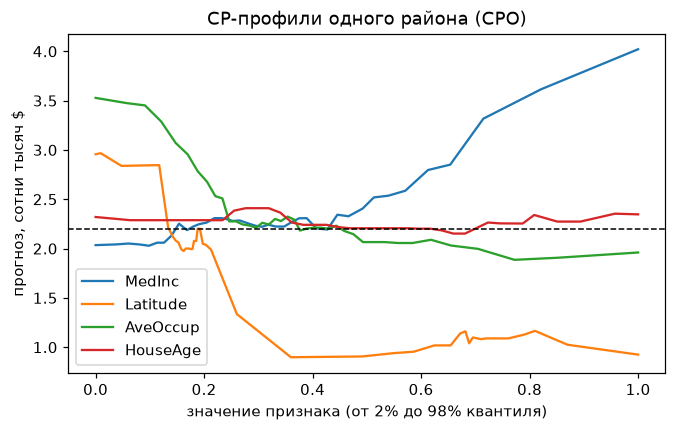

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
for f in ["MedInc", "Latitude", "AveOccup", "HouseAge"]:
    gv = np.quantile(Gtr[f], np.linspace(0.02, 0.98, 40))
    Zg = pd.concat([x0] * len(gv), ignore_index=True); Zg[f] = gv
    ax.plot((gv - gv.min()) / (gv.max() - gv.min()), hgb.predict(Zg), label=f)
ax.axhline(f0, color="k", ls="--", lw=1); ax.set_xlabel("значение признака (от 2% до 98% квантиля)"); ax.set_ylabel("прогноз, сотни тысяч $")
ax.set_title("CP-профили одного района (CPO)"); ax.legend();

**В чём измеряется.** Среднее абсолютное отклонение прогноза от $f(x)$ — в единицах цели, сотнях тысяч долларов.

### На что обращать внимание

- **Это локальная важность:** у другого объекта порядок признаков другой. Здесь у района сильнее всего прогноз качается по долготе и широте, доход — на пятом месте.
- **Направление эффекта осцилляция не показывает** — только величину.
- **Значения признака берутся независимо от остальных**, поэтому при коррелированных признаках та же экстраполяция, что у PDP и ICE.
- **Осцилляции не складываются в прогноз** — в отличие от SHAP (занятие 05).

## 2.2. ICE: CPO-кривые всех объектов

### Блок «Теория»

**ICE** (Goldstein et al., 2015) — CP-профили всех объектов на одном графике:
$$\mathrm{ICE}_i(v) = f(v, x_{i,C}),$$
где $C$ — все признаки, кроме $j$. **Центрированные ICE** (c-ICE): $\mathrm{ICE}_i(v) - \mathrm{ICE}_i(v_0)$ — каждая кривая начинается в нуле, и видно только изменение прогноза.

**Пример.** Как цена квартиры зависит от площади? Для каждой квартиры спрашиваем модель «а если бы у неё было 30 м²?», «а если 100 м²?» — получаем по кривой на квартиру. Проблема: «однушка в 100 м²» в данных не встречается, и модель отвечает о том, чего не видела.

### Как устроен код
```
для признака x1, для v из сетки:
    в каждом объекте x1 ← v, предсказать
ICE ← кривая каждого объекта; нарисовать обычные и центрированные
```

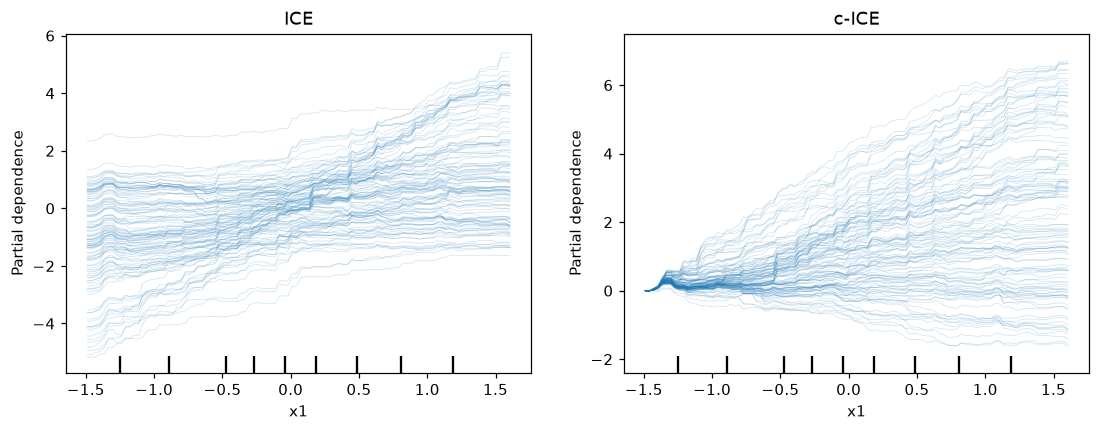

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sample = Xte.sample(200, random_state=0)
PartialDependenceDisplay.from_estimator(gbm, sample, ["x1"], kind="individual", ax=axs[0], subsample=120, random_state=0,
                                        ice_lines_kw={"alpha": 0.2}, pd_line_kw={"color": "tab:orange", "lw": 3})
PartialDependenceDisplay.from_estimator(gbm, sample, ["x1"], kind="individual", centered=True, ax=axs[1], subsample=120, random_state=0,
                                        ice_lines_kw={"alpha": 0.2}, pd_line_kw={"color": "tab:orange", "lw": 3})
axs[0].set_title("ICE"); axs[1].set_title("c-ICE");

**В чём измеряется.** По оси Y — прогноз модели в единицах $y$ (на центрированном графике — изменение прогноза относительно левого края сетки). По оси X — значение $x_1$.

### На что обращать внимание

- **Параллельные кривые** — эффект одинаков у всех объектов. **Расходящиеся** — эффект зависит от других признаков. Здесь кривые расходятся веером из-за взаимодействия $2x_1x_3$.
- **При коррелированных признаках ICE экстраполирует:** подставленное значение может не встречаться вместе с остальными признаками объекта.
- **Много кривых трудно читать:** берут подвыборку и центрируют.

## 2.3. ICE на California Housing

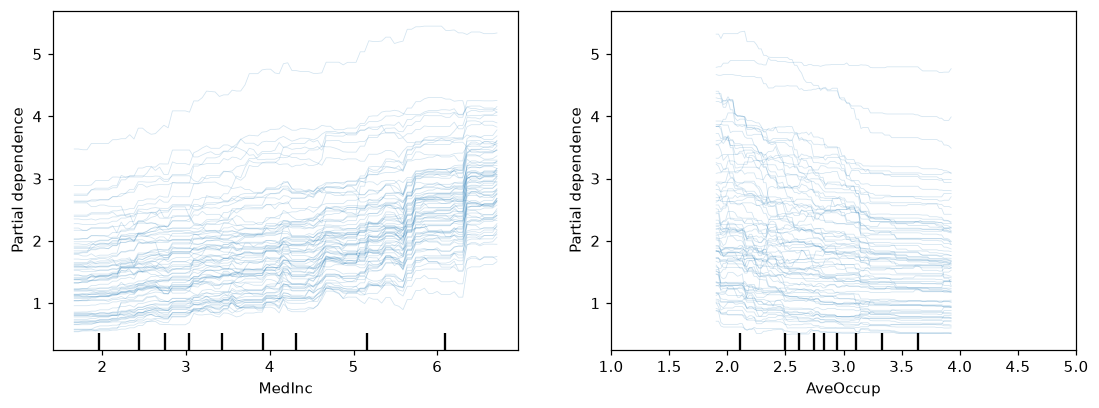

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
PartialDependenceDisplay.from_estimator(hgb, Gte.sample(300, random_state=0), ["MedInc", "AveOccup"], kind="individual", subsample=80,
                                        random_state=0, ax=axs, ice_lines_kw={"alpha": 0.2})
axs[1].set_xlim(1, 5);

**В чём измеряется.** Прогноз — медианная стоимость дома, сотни тысяч долларов. `MedInc` — медианный доход, десятки тысяч долларов в год; `AveOccup` — среднее число жильцов на дом.

### На что обращать внимание

- **Параллельные кривые** — эффект похож у всех объектов. Здесь так у дохода.
- **Расходящиеся кривые** — эффект зависит от других признаков. Здесь у числа жильцов: у одних районов прогноз падает сильно, у других почти не меняется.
- **ICE описывает модель, а не мир**: «если бы в этом районе жило больше людей на дом» — вопрос о прогнозе, а не о реальных ценах.

## 2.4. d-ICE

### Блок «Теория»

**Derivative ICE** (Goldstein et al., 2015) — производная ICE-кривой по признаку:
$$\mathrm{dICE}_i(v) = \frac{\partial f(v, x_{i,C})}{\partial v}.$$
Если взаимодействий с признаком нет, $f(x) = g(x_j) + h(x_C)$, и производные всех кривых совпадают: $\partial f / \partial x_j = g'(x_j)$. Разброс d-ICE-кривых означает, что эффект признака зависит от других. В статье ICE-кривые перед дифференцированием сглаживают.

**Пример.** Два бегуна в гору: важно не то, на какой высоте каждый (уровень ICE), а насколько круто дорога поднимается у каждого (наклон). Если у всех одинаковый подъём — эффект общий; если у одних круче — он зависит от того, по какой тропе идёт бегун.

### Как устроен код
```
ICE ← partial_dependence(kind="individual") для x1 на подвыборке
сгладить каждую кривую скользящим средним
dICE ← численная производная по сетке
средний наклон каждого объекта сравнить с его x3
```

корреляция наклона с x3: 0.99


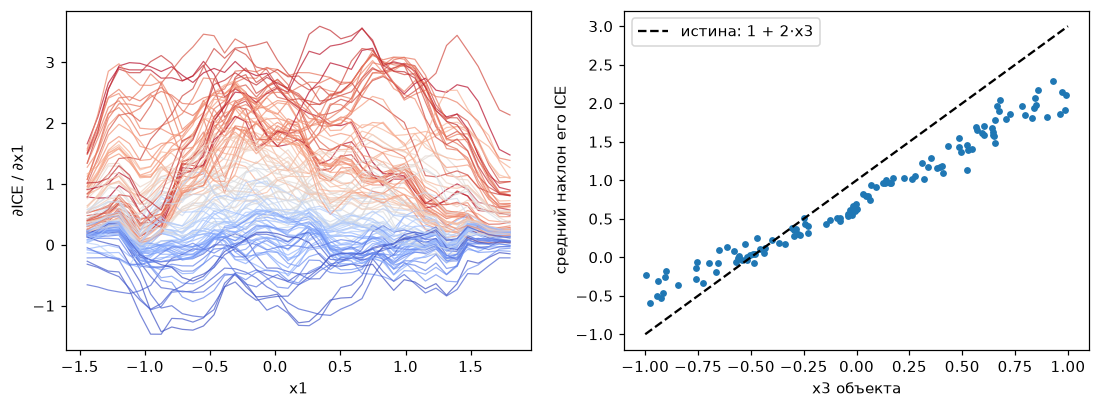

In [11]:
from sklearn.inspection import partial_dependence
from scipy.ndimage import uniform_filter1d
sub = Xte.sample(120, random_state=0)
res = partial_dependence(gbm, sub, ["x1"], kind="individual", grid_resolution=41)
grid, ice = res["grid_values"][0], res["individual"][0]
dice = np.gradient(uniform_filter1d(ice, size=7, axis=1, mode="nearest"), grid, axis=1)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
cmap = plt.get_cmap("coolwarm")
for r in range(len(sub)): axs[0].plot(grid, dice[r], color=cmap((sub.x3.values[r] + 1) / 2), lw=0.8, alpha=0.7)
axs[0].set_xlabel("x1"); axs[0].set_ylabel("∂ICE / ∂x1")
slope = dice[:, (grid > -1.5) & (grid < 1.5)].mean(1)
axs[1].scatter(sub.x3, slope, s=12); axs[1].plot([-1, 1], [-1, 3], "k--", label="истина: 1 + 2·x3")
axs[1].set_xlabel("x3 объекта"); axs[1].set_ylabel("средний наклон его ICE"); axs[1].legend()
print("корреляция наклона с x3:", round(np.corrcoef(sub.x3, slope)[0, 1], 2))

**В чём измеряется.** Производная — изменение прогноза (в единицах $y$) на единицу $x_1$.

### На что обращать внимание

- **Разброс d-ICE — признак взаимодействия;** если взаимодействий нет, все кривые совпадают. Здесь средний наклон ICE почти полностью определяется $x_3$ (корреляция 0,99), как и в истинной модели $1 + 2x_3$.
- **У деревьев ICE ступенчатые,** и численную производную приходится сглаживать; от ширины сглаживания зависит картинка.
- **d-ICE наследует экстраполяцию ICE** при коррелированных признаках.

---
# Часть 3. PDP: среднее ICE-кривых

### Блок «Теория»

**PDP** (Friedman, 2001) — среднее ICE-кривых, то есть усреднение CP-профилей по всем объектам:
$$\mathrm{PD}_j(v) = \mathbb E_{X_C}\big[f(v, X_C)\big] \approx \frac1n \sum_{i=1}^n f(v, x_{i,C}) = \frac1n \sum_{i=1}^n \mathrm{ICE}_i(v).$$
Отвечает на вопрос, как в среднем меняется прогноз, если признак принимает значение $v$.

**Предположение PDP** — признак $j$ независим от остальных. Иначе PDP подставляет значения в объекты, где такой комбинации не бывает, и усредняет прогнозы модели на этих выдуманных объектах.

**Пример.** Средний прогноз цены по всем квартирам города, если бы у каждой была площадь $v$. Если однокомнатные квартиры площадью 100 м² не встречаются, в среднее попадают ответы модели о несуществующих квартирах.

### Как устроен код
```
для v из сетки: в каждом объекте x1 ← v, предсказать, усреднить
нарисовать PDP поверх ICE
```

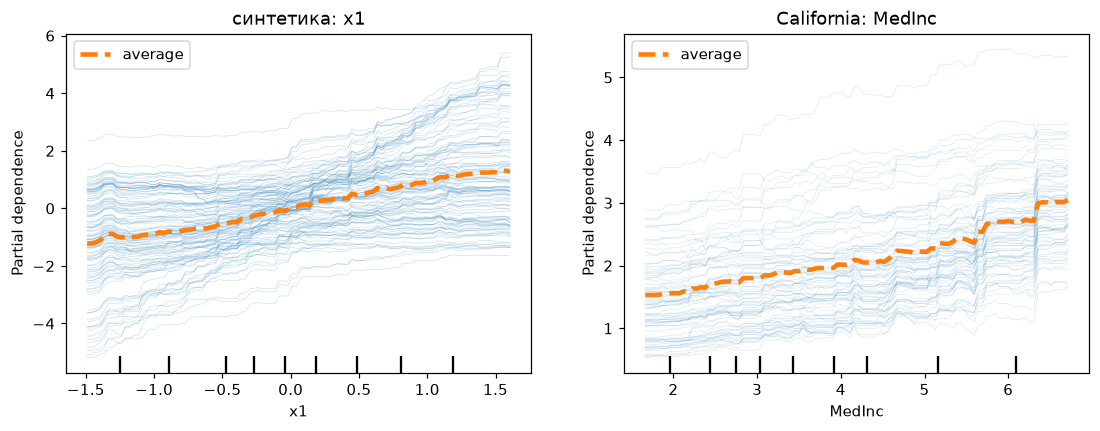

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
PartialDependenceDisplay.from_estimator(gbm, Xte.sample(200, random_state=0), ["x1"], kind="both", ax=axs[0], subsample=120, random_state=0,
                                        ice_lines_kw={"alpha": 0.2}, pd_line_kw={"color": "tab:orange", "lw": 3})
PartialDependenceDisplay.from_estimator(hgb, Gte.sample(300, random_state=0), ["MedInc"], kind="both", ax=axs[1], subsample=80, random_state=0,
                                        ice_lines_kw={"alpha": 0.15}, pd_line_kw={"color": "tab:orange", "lw": 3})
axs[0].set_title("синтетика: x1"); axs[1].set_title("California: MedInc");

**В чём измеряется.** По оси Y — прогноз в единицах цели (слева — $y$ синтетики, справа — сотни тысяч долларов). Оранжевая линия — PDP, тонкие — ICE.

### На что обращать внимание

- **PDP — среднее ICE.** Если ICE-кривые расходятся, PDP прячет разброс.
- **Ровная PDP не значит, что признак не важен.** Пусть $y = x_1 x_3$, $x_3 = \pm 1$ равновероятно. При $x_3 = 1$ прогноз растёт по $x_1$, при $x_3 = -1$ — падает, в среднем — ровная линия. Признак при этом вместе с $x_3$ полностью определяет ответ: это видно на ICE (кривые веером), на 2D PDP и по permutation importance.
- **При коррелированных признаках PDP экстраполирует.** На синтетике 47% точек, в которых PDP вызывает модель для $x_1$, лежат дальше трёх стандартных отклонений от облака данных $(x_1, x_2)$. Там модель не училась, и деревья просто продолжают крайние значения.
- **В scikit-learn для бустинга PDP по умолчанию считается методом `recursion`** — по весам листьев обучающей выборки, а не перебором по вашим объектам; для ICE используется перебор.
- **Для классификации** указывайте, что на оси Y: вероятность или логит.

---
# Часть 4. ALE и взаимодействия

## 4.1. ALE

### Блок «Теория»

**Почему не просто среднее среди похожих объектов.** M-plot берёт объекты с $x_1 \approx v$ и усредняет их прогнозы. Экстраполяции нет, но у объектов с большим $x_1$ и $x_2$ большой, и в кривую подмешивается эффект $x_2$. Apley и Zhu (2020) сравнивают PDP и M-plot и предлагают ALE.

**ALE** (accumulated local effects). Ось признака делят на интервалы $(z_{k-1}, z_k]$ по квантилям. В каждом интервале берут только объекты, которые в нём лежат, и считают среднюю разность прогнозов при сдвиге $x_j$ от левой границы к правой:
$$\Delta_k = \frac{1}{n_k} \sum_{i:\, x_{ij} \in (z_{k-1}, z_k]} \big[f(z_k, x_{i,C}) - f(z_{k-1}, x_{i,C})\big].$$
Разности накапливают слева направо и центрируют:
$$\mathrm{ALE}(v) = \sum_{k:\, z_k \le v} \Delta_k - \text{const}.$$

Экстраполяции нет: объекты сдвигаются только внутри своего узкого интервала. Эффекты не смешиваются: разность берётся при одних и тех же $x_{i,C}$, вклад $x_2$ вычитается.

**Пример.** Как рост влияет на вес? M-plot: сравнить средний вес людей ростом 160 и 190 см — но высокие чаще мужчины, и в разницу подмешается пол. PDP: спросить «а если бы этот ребёнок был ростом 190 см?» — бессмысленный объект. ALE: для людей ростом около 170 см спросить «что если бы они были на 2 см выше?», для людей около 180 — то же самое, и сложить эти маленькие шаги.

### Как устроен код
```
сетка xs по x1
f ← обёртка над predict (effector передаёт numpy-массив)
PDP ← effector.PDP(данные, f).eval(x1, xs)
ALE ← effector.ALE(данные, f).eval(x1, xs)
M-plot ← для v из xs: среднее прогнозов объектов с |x1 − v| < 0,25
сравнить наклоны с истинным (1)
```

PDP: наклон 0.86
M-plot: наклон 1.81
ALE: наклон 1.03


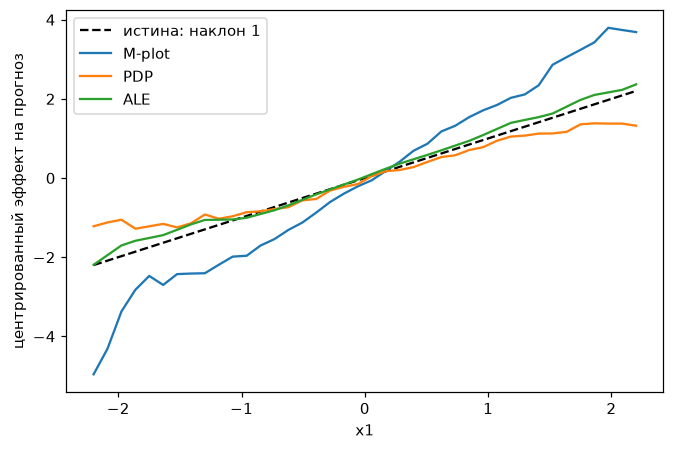

In [13]:
xs = np.linspace(-2.2, 2.2, 40)
f = lambda Z: gbm.predict(pd.DataFrame(Z, columns=X.columns))   # effector передаёт numpy-массив
pdp_x1 = effector.PDP(Xte.values, f, random_state=0).eval(feature=0, xs=xs, centering=True)
ale_x1 = effector.ALE(Xte.values, f, random_state=0).eval(feature=0, xs=xs, centering=True)
pred = gbm.predict(Xte)
mplot = np.array([pred[np.abs(Xte.x1.values - v) < 0.25].mean() for v in xs]); mplot -= mplot[np.abs(xs) < 2].mean()
plt.figure(figsize=(7, 4.5))
plt.plot(xs, xs - xs.mean(), "k--", label="истина: наклон 1")
plt.plot(xs, mplot, label="M-plot"); plt.plot(xs, pdp_x1, label="PDP"); plt.plot(xs, ale_x1, label="ALE")
plt.xlabel("x1"); plt.ylabel("центрированный эффект на прогноз"); plt.legend()
mid = (xs > -1.5) & (xs < 1.5)
for name, v in [("PDP", pdp_x1), ("M-plot", mplot), ("ALE", ale_x1)]:
    print(f"{name}: наклон {np.polyfit(xs[mid], v[mid], 1)[0]:.2f}")

**В чём измеряется.** Центрированный эффект — изменение прогноза в единицах $y$ относительно среднего; наклон — изменение прогноза на единицу $x_1$.

### На что обращать внимание

- **При коррелированных признаках PDP экстраполирует, M-plot смешивает эффекты, ALE — нет.** Здесь наклоны: PDP 0,86 (загибается на краях), M-plot 1,81 (почти эффект $x_1 + x_2$), ALE 1,03 при истинном 1.
- **При независимых признаках PDP и ALE совпадают.**
- **Число интервалов — компромисс:** мало — грубая кривая, много — в каждом интервале мало объектов и кривая шумит.
- **ALE говорит только о той области, где есть данные;** индивидуальных кривых, как ICE, у ALE нет.
- **Для категориальных признаков нужен порядок категорий:** разности накапливаются по нему.
- **ALE дешевле PDP:** два прогноза на объект, а не по одному на каждую точку сетки.
- **Есть 2D ALE** для пар признаков: он показывает чистое взаимодействие без одномерных эффектов.

## 4.2. Взаимодействия: 2D PDP и H-статистика

### Блок «Теория»

Если эффект $x_1$ зависит от $x_3$, одномерные кривые этого не покажут. **2D PDP** подставляет пару значений во все объекты:
$$\mathrm{PD}_{jk}(v, w) = \frac1n \sum_i f(v, w, x_{i,C}).$$

**H-статистика** (Friedman & Popescu, 2008) превращает это в число — долю эффекта пары, которую не объясняет сумма одномерных эффектов:
$$H^2_{jk} = \frac{\sum_i \big[\mathrm{PD}_{jk}(x_{ij}, x_{ik}) - \mathrm{PD}_j(x_{ij}) - \mathrm{PD}_k(x_{ik})\big]^2}{\sum_i \mathrm{PD}^2_{jk}(x_{ij}, x_{ik})}.$$
Все частные зависимости центрированы и вычислены в точках объектов $i$. 0 — взаимодействия нет, 1 — эффект пары целиком из взаимодействия. H-статистику мы пока считать не будем оставим под дз 2.

**Пример.** Удобрение и полив: каждое по отдельности даёт прибавку урожая, но вместе — больше, чем сумма двух прибавок. Эта добавка и есть взаимодействие.

### Как устроен код
```
для пары (x1, x3), для сетки значений (v, w):
    в каждом объекте x1 ← v, x3 ← w; среднее прогнозов
нарисовать карту
```

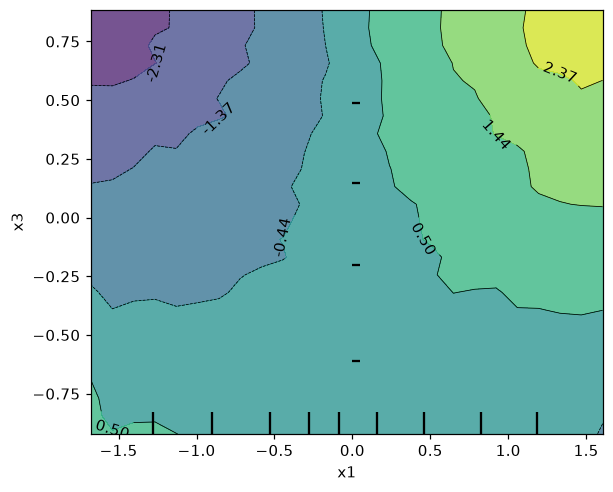

In [14]:
fig, ax = plt.subplots(figsize=(6, 5))
PartialDependenceDisplay.from_estimator(gbm, Xte.sample(500, random_state=0), [("x1", "x3")], ax=ax, grid_resolution=25);

**В чём измеряется.** Цвет и линии уровня — средний прогноз модели в единицах $y$ при данной паре значений $(x_1, x_3)$.

### На что обращать внимание

- **Если линии уровня не параллельны осям и наклон по одному признаку меняется с другим — есть взаимодействие.** Здесь при $x_3 \approx 1$ прогноз круто растёт по $x_1$, при $x_3 \approx -1$ — падает.
- **2D PDP наследует предположение независимости и экстраполяцию PDP.**
- **H-статистика мерит взаимодействие, а не корреляцию:** у пары почти одинаковых признаков H² может быть около нуля. Здесь у $x_1 \times x_3$ H² ≈ 0,58 (настоящее взаимодействие), у $x_1 \times x_2$ — около 0,02, хотя признаки почти одинаковые, у шумового $x_1 \times x_4$ — 0,002.
- **Большой H² при крошечном общем эффекте пары ничего не значит** — смотрите и на сам эффект. Считать H² дорого — частные зависимости нужны в каждой точке, стоимость квадратична по числу объектов, — поэтому его считают на подвыборке. H² наследует экстраполяцию PDP.

---
# Часть 5. Permutation importance

## 5.1. Определение

### Блок «Теория»

После визуальных методов — сводная числовая мера. **Идея.** Если модель опирается на признак, то, если его испортить, качество упадёт. Портим так: перемешиваем столбец признака между объектами. Распределение признака остаётся прежним, но его связь с остальными признаками и с ответом разрушена. Модель **не переобучается**.

**Общее определение.** Для батча $X = \{x^1, \dots, x^n\}$ и признака $i$ строим батч $X^{\pi_i}$: значения признака $i$ перемешаны случайной перестановкой $\pi$, у объекта $j$ все признаки свои, а на месте $i$-го — значение объекта $\pi(j)$:
$$X^{\pi_i} = \big\{(x^1_{-i}, x^{\pi(1)}_i), \dots, (x^n_{-i}, x^{\pi(n)}_i)\big\}.$$
Важность — ожидаемое изменение потерь $\mathcal L$ при такой перестановке:
$$\mathrm{Perm}_i(X) = \mathbb E_\pi\big[\mathcal L(f(X^{\pi_i})) - \mathcal L(f(X))\big].$$
Метод требует батча объектов: значения для подмены берутся у других примеров. Перестановка случайна, поэтому важность — случайная величина; матожидание оценивают средним по $K$ перестановкам.

Для случайного леса так считал важности Брейман (2001); на любую модель метод обобщили Fisher, Rudin, Dominici (2019).

**Пример.** Чтобы понять, насколько повару нужна соль, не надо учить его готовить заново: подмените соль на случайную приправу и посмотрите, насколько хуже станет суп.

## 5.2. Три записи важности

### Блок «Теория»

Сравнить потери до и после перестановки можно отношением или разностью. Ниже $e$ — ошибка (например, MSE), $q$ — метрика качества (например, $R^2$), индекс perm — после $k$-й перестановки признака $i$.

**Отношение ошибок** — исходная запись, model reliance:
$$\mathrm{MR}_i = \frac1K \sum_{k=1}^K \frac{e_{\mathrm{perm},k}}{e_{\mathrm{orig}}}.$$
$\mathrm{MR} = 1$ — модель не опирается на признак; $\mathrm{MR} \to 2$ — без признака ошибка удваивается; $\mathrm{MR} < 1$ — признак связан с другим признаком или вносит шум.

**Разность ошибок:**
$$\mathrm{PI}_i = \frac1K \sum_{k=1}^K e_{\mathrm{perm},k} - e_{\mathrm{orig}}.$$

**Разность качества** — так считают `sklearn.inspection.permutation_importance` и `eli5`:
$$\mathrm{PI}_i = q_{\mathrm{orig}} - \frac1K \sum_{k=1}^K q_{\mathrm{perm},k}.$$
В обеих разностях $> 0$ — признак нужен, $\approx 0$ — нет.

Внутри одной модели отношение и разность ошибок ранжируют признаки одинаково: $e_{\mathrm{orig}}$ общий. Разность MSE и разность $R^2$ на одной выборке тоже пропорциональны: $R^2 = 1 - \mathrm{MSE}/\mathrm{Var}(y)$. Расходятся записи при сравнении моделей с разным уровнем ошибки: прирост ошибки на 0,5 — это удвоение для точной модели и мелочь для грубой. Поэтому в отчёте указывают, какая запись использована.

**Пример.** «Суп стал хуже на две ложки соли» — разность; «суп стал вдвое хуже» — отношение. У повара, который и так готовит плохо, те же две ложки — малая доля.

### Как устроен код
```
для модели в (бустинг, линейная регрессия):
    e_orig ← MSE модели на test
    ΔMSE_i ← permutation_importance(scoring = MSE)    # разность ошибок
    ΔR²_i  ← permutation_importance(scoring = R²)     # разность качества
    MR_i   ← (e_orig + ΔMSE_i) / e_orig               # отношение ошибок
сравнить три записи внутри модели и между моделями
```

In [15]:
from sklearn.linear_model import LinearRegression
lin = LinearRegression().fit(Xtr, ytr)
tabs = {}
for name, m in [("бустинг", gbm), ("линейная", lin)]:
    e0 = np.mean((m.predict(Xte) - yte) ** 2)
    d_err = permutation_importance(m, Xte, yte, scoring="neg_mean_squared_error", n_repeats=20, random_state=0).importances_mean
    d_q = permutation_importance(m, Xte, yte, scoring="r2", n_repeats=20, random_state=0).importances_mean
    print(f"{name}: MSE на тесте = {e0:.3f}")
    tabs[name] = pd.DataFrame({"MR = e_perm / e_orig": (e0 + d_err) / e0, "e_perm − e_orig (MSE)": d_err,
                               "q_orig − q_perm (R²)": d_q}, index=X.columns)
pd.concat(tabs).round(3)

бустинг: MSE на тесте = 0.123
линейная: MSE на тесте = 1.307


MR = e_perm / e_orig  e_perm − e_orig (MSE)  q_orig − q_perm (R²)
бустинг  x1                22.307                  2.612                 0.546
         x2                25.691                  3.026                 0.633
         x3                21.055                  2.458                 0.514
         x4                 0.987                 -0.002                -0.000
линейная x1                 2.578                  2.061                 0.431
         x2                 2.259                  1.645                 0.344
         x3                 0.999                 -0.002                -0.000
         x4                 0.998                 -0.003                -0.001

**В чём измеряется.** MR — безразмерное отношение, 1 — нет опоры на признак. Разность ошибок — в единицах MSE, то есть в квадратах единиц $y$. Разность $R^2$ — безразмерная.

### На что обращать внимание

- **Внутри одной модели три записи дают один и тот же порядок признаков.** Здесь у бустинга порядок $x_2, x_1, x_3, x_4$ во всех трёх колонках; колонки $\Delta$MSE и $\Delta R^2$ отличаются множителем $\mathrm{Var}(y)$.
- **Между моделями записи расходятся.** У линейной регрессии MSE 1,31 против 0,12 у бустинга. Приросты MSE у $x_1$ сравнимы (2,06 и 2,61), а отношения — 2,6 и 22. Сравнивая важности разных моделей, называйте запись.
- **У линейной регрессии важность $x_3$ — ноль:** $x_3$ входит в $y$ только через $x_1 x_3$, а линейная модель взаимодействий не видит. Важность описывает модель, а не связь в данных — подробнее в разделе 5.10.
- **MR около 1 и разности около 0 у шумового $x_4$** — у обеих моделей.
- **Отрицательная разность или MR $< 1$** на конечной выборке бывает у бесполезного признака: случайная перестановка чуть улучшила метрику.

## 5.3. Перестановка — метод на основе вмешательства

Перестановка — частный случай общего класса: испортить вход по правилу и посмотреть, как изменится выход. Методы класса отличаются тем, чем заменяют признак: перестановка — значением случайного другого объекта (отсюда $\mathbb E_\pi$ и $K$), абляция — фиксированным baseline $b$, окклюзия — baseline на регионе изображения, RISE — случайными масками. Выбор замены задаёт вопрос, на который отвечает метод; абляцию, окклюзию и RISE разбираем на занятии 06.

![Методы на основе вмешательства](img/interventions.png)

## 5.4. Сколько перестановок нужно на самом деле

### Блок «Теория»

У метода два гиперпараметра: функция ошибки или метрика (она не обязана совпадать с итоговой метрикой задачи) и число перестановок $K$.

**Сколько всего различных переставленных колонок.** Если признак принимает $m$ различных значений, и значение $i$ встречается $k_i$ раз,
$$P = \frac{n!}{k_1! \cdot \ldots \cdot k_m!}.$$

**Перебирать их не нужно.** При случайной перестановке объект $j$ получает значение объекта $l$ с вероятностью $1/n$ для любого $l$, включая самого себя. Поэтому матожидание ошибки по всем перестановкам равно среднему по всем $n^2$ упорядоченным парам «подставить объекту $j$ значение объекта $l$» — это $n^2$ вызовов модели. Если $e_{\mathrm{switch}}$ — средняя ошибка по парам с $j \ne l$, то
$$\mathbb E_\pi\big[e_{\mathrm{perm}}\big] = \frac{n-1}{n}\, e_{\mathrm{switch}} + \frac1n\, e_{\mathrm{orig}}.$$
Перестановка с вероятностью $1/n$ возвращает объекту его значение, поэтому важность немного занижена: на 20% при $n = 5$, на 0,1% при $n = 1000$. Fisher, Rudin, Dominici (2019) берут $e_{\mathrm{switch}}$ — пары без диагонали.

| Что считаем | Вызовов модели | Нужно ли $K$ |
|---|---|---|
| все перестановки строк | $n!$ | — |
| точное среднее по упорядоченным парам | $n^2$ | нет |
| пары без диагонали ($e_{\mathrm{switch}}$) | $n(n-1)$ | нет |
| разбить выборку пополам, сравнивать между половинами | $\approx n$ | нет |
| Монте-Карло (библиотеки) | $K \cdot n$ | да |

**Оценка случайна**, поэтому смотрят на интервал: `permutation_importance` возвращает все $K$ значений в `importances` и их стандартное отклонение в `importances_std`.

**Пример.** Чтобы узнать, насколько класс хуже пишет диктант, если перепутать тетради, не нужно перебирать все способы раздать тетради. Достаточно для каждой пары учеников проверить, как один справится с тетрадью другого, и усреднить.

## 5.5. Считать на тесте, а не на обучении

### Блок «Теория»

**Где считать.** На обучении PI показывает, на что модель опиралась, подгоняясь, — включая шум, который она запомнила. На тесте — что ей нужно для прогноза на новых данных.

**Пример.** Чтобы понять, насколько повару нужна соль, не надо учить его готовить заново: подмените соль на случайную приправу и посмотрите, насколько хуже станет суп. Если суп не изменился — соль этому повару не нужна.

### Как устроен код
```
California + признак-пустышка random_num
лес ← обучить на train
для набора в (train, test):
    s₀ ← R² леса на наборе
    для каждого признака j, 5 раз:
        перемешать столбец j, s_k ← R²
    PI_j ← s₀ − среднее(s_k)
сравнить PI на train и на test
```

In [16]:
Xc = Cg.copy(); Xc["random_num"] = np.random.default_rng(1).normal(0, 1, len(Xc))   # признак-пустышка
Ctr, Cte, cytr, cyte = train_test_split(Xc, yc, test_size=0.25, random_state=0)
rf = RandomForestRegressor(n_estimators=150, random_state=0, n_jobs=-1).fit(Ctr, cytr)
pi_tr = permutation_importance(rf, Ctr.iloc[:4000], cytr[:4000], n_repeats=5, random_state=0, n_jobs=-1)
pi_te = permutation_importance(rf, Cte, cyte, n_repeats=5, random_state=0, n_jobs=-1)
pd.DataFrame({"PI на обучении": pi_tr.importances_mean, "PI на тесте": pi_te.importances_mean}, index=Xc.columns).round(3).sort_values("PI на тесте", ascending=False)

,PI на обучении,PI на тесте
MedInc,0.942,0.792
Latitude,0.409,0.387
Longitude,0.337,0.294
AveOccup,0.297,0.199
HouseAge,0.125,0.070
AveRooms,0.077,0.029
AveBedrms,0.037,0.009
Population,0.031,0.007
random_num,0.016,0.000


**В чём измеряется.** Падение $R^2$ после перемешивания признака — безразмерное. Значение около нуля или чуть ниже нуля значит, что признак модели не нужен: после перемешивания качество не изменилось или случайно чуть выросло.

### На что обращать внимание

- **PI на обучении и на тесте отвечают на разные вопросы.** На обучении видна опора на запомненный шум. Здесь у `random_num` на обучении 0,016, на тесте 0,000; важности настоящих признаков на обучении тоже выше — лес переобучен.
- **Модель не переобучается.** PI говорит, насколько нужен признак **этой** модели, а не насколько он полезен вообще.
- **Перестановок несколько.** Одна перестановка даёт случайный результат; смотрите на среднее и разброс (`importances_std`).

## 5.6. Ограничения permutation importance

При использовании метода эти ограничения необходимо учитывать.

| Ограничение | Что происходит |
|---|---|
| Вычисления | каждый признак переставляют много раз, и на каждой перестановке прогоняют модель |
| Зависимость признаков | маргинальное распределение признака (те же значения и частоты) сохраняется, совместное рвётся: появляются объекты вне данных |
| Коррелированные признаки — ошибка в обе стороны | **занижение:** модель опирается на один признак пары, второй при перестановке почти ничего не меняет (об этом предупреждает документация scikit-learn); **избыточность:** модель использует оба, оба получают высокую важность, хотя любой можно убрать почти без потерь |
| Дисбаланс категорий | чем реже категория, тем ниже важность — смещение по построению, $K$ его не исправляет |

Следующие разделы разбирают эти ограничения на примерах.

## 5.7. Коррелированные признаки и drop-column (LOCO)

### Блок «Теория»

Перемешав $x_1$, мы получаем объекты, которых в данных не бывает: $x_1 = 2$ при $x_2 = -1$, хотя признаки скоррелированы на 0,9. На таких объектах модель не училась, и её ошибка там — экстраполяция. PI мерит и её, а не только полезность признака.

**Drop-column importance**, она же **LOCO** (leave-one-covariate-out; Lei et al., 2018), отвечает на другой вопрос: насколько хуже станет модель, если признака не будет вовсе. Признак удаляют и модель **переобучают**:
$$\mathrm{DC}_j = s(f, X, y) - s\big(f_{-j}, X_{-j}, y\big),$$
где $f_{-j}$ — модель, обученная без признака $j$. Если есть коррелированный сосед, он подхватывает информацию, и падение маленькое. Цена — одно обучение на каждый признак.

Ещё два способа: **групповая важность** — коррелированные признаки перемешивают одной перестановкой, и объекты внутри группы остаются правдоподобными; **условная важность** (Strobl et al., 2008) — признак перемешивают только среди объектов с похожими значениями соседей. Групповую важность вы реализуете в ДЗ-2.

**Пример.** В команде два одинаково сильных защитника. Если на одну игру поставить вместо одного из них случайного игрока с трибуны (перемешивание), команда развалится: схема рассчитана на пару. Если тренер заранее знает, что одного не будет, и перестроит игру (переобучение), второй защитник справится — потеря небольшая.

### Как устроен код
```
PI ← permutation_importance(модель, test)
для каждого признака j:
    модель_без_j ← обучить на train без столбца j
    DC_j ← R²(модель) − R²(модель_без_j) на test
сравнить PI и DC
```

In [17]:
pi = permutation_importance(gbm, Xte, yte, n_repeats=20, random_state=0)
base = gbm.score(Xte, yte)
dc = {}
for c in X.columns:
    m = HistGradientBoostingRegressor(max_iter=300, random_state=0).fit(Xtr.drop(columns=c), ytr)
    dc[c] = base - m.score(Xte.drop(columns=c), yte)
pd.DataFrame({"permutation": pi.importances_mean, "drop-column": pd.Series(dc)}, index=X.columns).round(3)

,permutation,drop-column
x1,0.546,0.113
x2,0.633,0.049
x3,0.514,0.348
x4,-0.000,-0.001


**В чём измеряется.** Обе колонки — падение $R^2$ на тесте (безразмерное). Падение больше 1 возможно: $R^2$ становится отрицательным, если модель после порчи хуже константы.

### На что обращать внимание

- **При коррелированных признаках PI и drop-column расходятся.** PI создаёт объекты вне данных и мерит экстраполяцию модели; drop-column — потерю, когда сосед может заменить признак. Здесь PI у $x_1$ и $x_2$ — 0,55 и 0,63, drop-column — 0,11 и 0,05.
- **Перемешать $x_1$ и $x_2$ одной перестановкой — падение $R^2$ на 2,07**, больше суммы отдельных важностей (0,55 + 0,63 = 1,18). Падение больше 1 значит, что $R^2$ стал отрицательным: модель хуже константы. Групповую важность вы реализуете в ДЗ-2.
- **Низкая важность при коррелированном соседе не значит, что признак не связан с целью.** Модель могла опереться на соседа. Пример: у «площади в квадратных футах» PI почти ноль, у «площади в квадратных метрах» — большая. Вывод «площадь в футах не влияет на цену» неверен; верный — «модели этот признак почти не нужен при наличии соседа». Для решения об удалении — drop-column или групповая важность.
- **«Важность признака» — всегда ответ на конкретный вопрос.** Называйте метод и данные, на которых она посчитана.
- **У шумового признака обе важности около нуля** — здесь у $x_4$.

## 5.8. Дисбаланс категорий

### Блок «Теория»

Чистый случай: модель предсказывает ответ идеально, $f(x) = y$, метрика — MSE. До перестановки ошибка нулевая. После — каждый объект ошибается на величину подмены, и важность равна среднему квадрату сдвига значений признака. В среднем по перестановкам это удвоенная дисперсия признака:
$$\mathbb E\big[(x_{\pi(j)} - x_j)^2\big] = 2\,\mathrm{Var}(x) \;\; (\text{без поправки } (n-1)/n).$$
Для бинарного признака с долей единиц $p$ дисперсия $p(1-p)$, поэтому
$$\mathrm{PI} = 2p(1-p).$$

| Доля $p$ | 0,5 | 0,1 | 0,05 | 0,01 | 0,001 |
|---|---|---|---|---|---|
| PI | 0,5 | 0,18 | 0,095 | 0,0198 | 0,002 |
| Ниже, чем при $p = 0{,}5$ | 1× | 2,8× | 5,3× | 25× | 250× |

Сигнал в признаке один и тот же — меняется только частота. Перестановка сдвигает только строки с редкой категорией, остальные вносят в среднее ноль. Это **смещение по построению**, а не шум, и увеличение $K$ его не исправляет.

**Пример.** Признак «был ли дефолт», который встречается у одного клиента из ста, получит важность в 25 раз ниже сбалансированного признака, даже если он предсказывает цель идеально.

### Как устроен код
```
для p из (0,5; 0,3; 0,1; 0,05; 0,01):
    x ← бинарный признак, доля единиц p; модель f(x) = x, ответ y = x
    50 раз: перемешать x, ошибка ← среднее (x_перемешанный − x)²
    PI(p) ← среднее ошибок            # исходная ошибка = 0
нарисовать PI(p) и теорию 2p(1 − p)
```

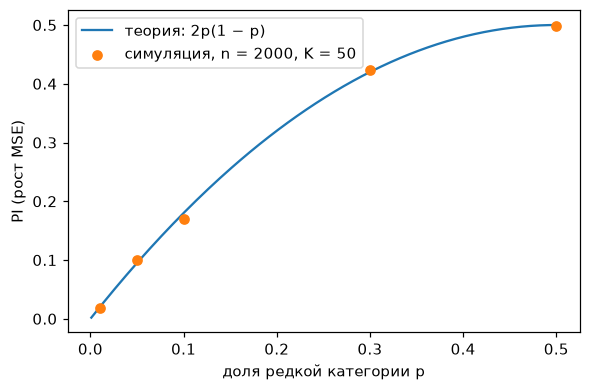

,p,симуляция,2p(1 − p)
0,0.50,0.4989,0.5000
1,0.30,0.4230,0.4200
2,0.10,0.1695,0.1800
3,0.05,0.0998,0.0950
4,0.01,0.0189,0.0198


In [18]:
rng_b = np.random.default_rng(0)
n_b, K_b = 2000, 50
ps = [0.5, 0.3, 0.1, 0.05, 0.01]
sim = []
for p in ps:
    xb = (rng_b.random(n_b) < p).astype(float)    # модель f(x) = x предсказывает y = x идеально
    sim.append(np.mean([np.mean((xb[rng_b.permutation(n_b)] - xb) ** 2) for _ in range(K_b)]))
g = np.linspace(0.001, 0.5, 200)
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(g, 2 * g * (1 - g), label="теория: 2p(1 − p)")
ax.scatter(ps, sim, color="C1", zorder=5, label=f"симуляция, n = {n_b}, K = {K_b}")
ax.set_xlabel("доля редкой категории p"); ax.set_ylabel("PI (рост MSE)"); ax.legend(); plt.show()
pd.DataFrame({"p": ps, "симуляция": sim, "2p(1 − p)": [2 * p * (1 - p) for p in ps]}).round(4)

**В чём измеряется.** Рост MSE; здесь $y \in \{0, 1\}$, поэтому PI — доля строк, которые перестановка испортила.

### На что обращать внимание

- **Симуляция ложится на теорию:** при $p = 0{,}01$ важность около 0,019 против 0,5 у сбалансированного признака.
- **Сравнивать PI признаков с сильно разной частотностью некорректно.** Низкая важность редкой категории не значит, что признак слабый.
- **Увеличение $K$ уменьшает разброс оценки, но не смещение.**
- **Тот же эффект у непрерывных признаков:** при той же силе связи важность растёт с дисперсией признака.

## 5.9. Пограничные случаи

### Блок «Теория»

Все случаи читаются по формуле $P = n!/(k_1! \cdot \ldots \cdot k_m!)$: чем меньше различных колонок, тем чаще перестановка возвращает исходную и тем меньше метод способен измерить. Пара $(j, l)$ «холостая», если у объектов одинаковое значение признака: подмена ничего не меняет. Доля холостых пар среди $n(n-1)$ пар без диагонали:
$$\frac{\sum_i k_i (k_i - 1)}{n(n-1)}.$$

- **Константный признак:** $P = 1$, перестановка ничего не делает, важность тождественно ноль при любом $K$. Ответ правильный, но вырожденный: не «измерили — мало», а «измерять было нечего».
- **Почти константный, 9 против 1 при $n = 10$:** $P = 10$. Каждая десятая перестановка возвращает исходную, а когда не возвращает — сдвигаются ровно две строки. Оценка держится на двух наблюдениях, её распределение дискретно, ноль среди значений — с вероятностью 0,1. Холостых пар 72 из 90.
- **Два объекта:** $P = 2$, с вероятностью 1/2 важность ноль; при равных значениях — константный случай.

### Как устроен код
```
для каждого столбца-примера:
    k_i ← сколько раз встречается каждое значение
    P ← n! / Π k_i!
    доля холостых пар ← Σ k_i(k_i − 1) / (n(n − 1))
```

In [19]:
from math import factorial
from collections import Counter
def n_distinct_perms(col):
    r = factorial(len(col))
    for k in Counter(col).values(): r //= factorial(k)
    return r
def idle_share(col):
    n_ = len(col)
    return sum(k * (k - 1) for k in Counter(col).values()) / (n_ * (n_ - 1))
cases = {"константа, n = 10": [0] * 10, "9 против 1, n = 10": [0] * 9 + [1],
         "поровну, n = 10": [0] * 5 + [1] * 5, "все разные, n = 10": list(range(10)), "два объекта": [0, 1]}
pd.DataFrame({"P": {c: n_distinct_perms(v) for c, v in cases.items()},
              "доля холостых пар": {c: idle_share(v) for c, v in cases.items()}}).round(3)

,P,доля холостых пар
"константа, n = 10",1,1.000
"9 против 1, n = 10",10,0.800
"поровну, n = 10",252,0.444
"все разные, n = 10",3628800,0.000
два объекта,2,0.000


### На что обращать внимание

- **Нулевая важность константного признака — не вывод о признаке**, а сообщение «измерять было нечего». Перед подсчётом PI посмотрите на число уникальных значений.
- **У почти константного признака оценка держится на нескольких строках** и сильно дискретна; доверительный интервал по $K$ перестановкам это покажет.
- **Даже у сбалансированного бинарного признака почти половина пар холостые** (20 из 45 неупорядоченных) — это и есть множитель $2p(1-p)$ из раздела 5.8.

## 5.10. Одни данные, две модели — разная важность

### Блок «Теория»

Задача «побитовое И»: $y = X_1 \text{ AND } X_2$, причём $X_1 = 1$ всегда влечёт $X_2 = 1$, так что на этих данных $y$ совпадает с $X_1$. Две модели одинаково идеальны (accuracy = 1): модель A опирается только на $X_1$ ($\hat y = X_1$), модель B считает $X_1 \text{ AND } X_2$.

| $X_1$ | $X_2$ | $X_2^*$ | $X_2^{**}$ | $y$ |
|---|---|---|---|---|
| 1 | 1 | 0 | 1 | 1 |
| 1 | 1 | 1 | 0 | 1 |
| 0 | 1 | 1 | 1 | 0 |
| 0 | 0 | 1 | 1 | 0 |

У модели A прогноз от $X_2$ не зависит: PI = 0. У модели B каждая из двух показанных перестановок портит одну строку из четырёх: accuracy 0,75, PI = 0,25. Не каждая перестановка портит строку: если ноль попадает в строку с $X_1 = 0$, прогноз не меняется. В среднем по всем 24 перестановкам PI модели B — 0,125.

Качество одинаковое, важность $X_2$ разная. Это **эффект Рашомона**: много одинаково хороших моделей по-разному используют признаки (термин Бреймана, 2001). Fisher, Rudin, Dominici (2019) вводят **model class reliance**: важность признака — не число, а интервал по множеству почти оптимальных моделей. Здесь — от 0 у модели A до 0,125 у модели B (0,25 по двум показанным перестановкам).

**Пример.** Два врача ставят одинаково верные диагнозы. Один смотрит только на анализ крови, другой — на кровь и давление. Спросите «насколько важно давление?» — у первого ответ «никак», у второго «важно», хотя данные и точность одни.

### Как устроен код
```
данные: таблица выше; модель A: ŷ = X1; модель B: ŷ = X1 AND X2
для каждой модели:
    PI на двух показанных перестановках X2* и X2**
    PI в среднем по всем 4! перестановкам X2
    условная: переставлять X2 только внутри групп с одинаковым X1
```

In [20]:
import itertools
X1 = np.array([1, 1, 0, 0]); X2 = np.array([1, 1, 1, 0]); y_and = X1 & X2
models = {"A: ŷ = X1": lambda a, b: a, "B: ŷ = X1 AND X2": lambda a, b: a & b}
shown = [np.array([0, 1, 1, 1]), np.array([1, 0, 1, 1])]          # X2* и X2**
all_perms = [X2[list(p)] for p in itertools.permutations(range(4))]
cond_perms = [X2[[*p, *q]] for p in itertools.permutations([0, 1]) for q in itertools.permutations([2, 3])]   # внутри X1 = 1 и X1 = 0
pi_acc = lambda m, perms: np.mean([1 - np.mean(m(X1, b) == y_and) for b in perms])   # accuracy исходной = 1
pd.DataFrame({"accuracy": {k: np.mean(m(X1, X2) == y_and) for k, m in models.items()},
              "PI, две показанные": {k: pi_acc(m, shown) for k, m in models.items()},
              "PI, все 24 перестановки": {k: pi_acc(m, all_perms) for k, m in models.items()},
              "PI условная": {k: pi_acc(m, cond_perms) for k, m in models.items()}})

,accuracy,"PI, две показанные","PI, все 24 перестановки",PI условная
A: ŷ = X1,1.0,0.00,0.000,0.0
B: ŷ = X1 AND X2,1.0,0.25,0.125,0.0


**В чём измеряется.** Падение accuracy — доля строк, которые перестановка испортила.

### На что обращать внимание

- **Важность — свойство модели, а не данных.** Одинаково точные модели дают важности 0 и 0,125. На практике обучают несколько почти одинаково хороших моделей и смотрят диапазон их важностей.
- **Оценка по двум перестановкам (0,25) вдвое выше точного среднего (0,125).** На четырёх объектах это и есть пограничный случай: перестановок мало, оценка дискретна.
- **Условная важность $X_2$ равна нулю у обеих моделей:** при известном $X_1$ признак $X_2$ ничего не добавляет. Обычная перестановка отвечает на вопрос «что модель берёт из признака», условная — «что признак добавляет сверх остальных».

## 5.11. Что делать: условная перестановка, LOCO, групповая важность, PIMP

### Блок «Теория»

- **Условная перестановка** (Strobl et al., 2008): значения признака берут из условного распределения при остальных признаках; на практике перемешивают внутри групп с похожими значениями коррелированных соседей. Это выбор распределения, из которого берут подставляемые значения, и тем самым выбор вопроса (термины — Chen, Janizek, Lundberg, Lee, 2020):
  - обычная (маргинальная) перестановка берёт значения из $P(X_i)$ — объяснение *true to the model*: описывает функцию $f$, в том числе на объектах вне данных, то есть всё, что модель берёт из признака;
  - условная берёт их из $P(X_i \mid X_{-i})$ — объяснение *true to the data*: учитывает зависимости признаков и показывает, что признак добавляет сверх соседей.

  Универсально верного выбора нет. Та же развилка встретится у SHAP (занятие 05).
- **LOCO / drop-column** (Lei et al., 2018): выбросить признак и переобучить. Чище, но одно обучение на каждый признак (раздел 5.7).
- **Групповая перестановка:** коррелированные признаки перемешивают одной перестановкой — насколько модели нужна вся группа. Её вы реализуете в ДЗ-2.
- **Corrected PIMP** (Altmann et al., 2010): многократно перемешивают целевую переменную, каждый раз переобучают модель и пересчитывают важности. Получается нулевое распределение «важности при отсутствии связи», сравнение с ним даёт p-value.

| Задача | Метод |
|---|---|
| быстрый дефолт | обычная перестановка на тесте |
| коррелированные признаки | условная или групповая |
| чистый вклад, есть ресурсы | LOCO |
| отделить значимые признаки от шумовых | PIMP |

Hooker, Mentch, Zhou (2021) разбирают, почему без перестановки, сохраняющей зависимость, или переобучения важность при коррелированных признаках мерит экстраполяцию.

---
## Итог

| Метод | Вопрос | Ломается, когда |
|---|---|---|
| Anchors | чего достаточно, чтобы решение осталось | маленькое покрытие; выбор окрестности |
| Контрфактуал | что изменить, чтобы решение поменялось | много вариантов; изменяемость признаков |
| CPO, осцилляции | что будет с прогнозом одного объекта | экстраполяция; локально |
| ICE, d-ICE | как зависит прогноз каждого объекта | те же экстраполяции; много кривых трудно читать |
| PDP | как в среднем прогноз зависит от признака | признаки коррелированы; среднее прячет разброс |
| ALE | локальный эффект там, где есть данные | нет разброса по объектам; выбор интервалов |
| 2D PDP, H² | есть ли взаимодействие пары | дорого; H² ≠ сила эффекта |
| Permutation importance | насколько модели нужен признак | признаки коррелированы: экстраполяция; редкие категории; мало различных значений; важность — свойство модели |
| Drop-column (LOCO) | что будет без признака, если переучить | дорого; коррелированный сосед подхватывает |

### Общий вывод

Все методы занятия — извлечение характеристик признаков из поведения модели: якорь — правило с точностью и покрытием, контрфактуал — расстояние между векторами, CPO — осцилляция прогноза, ICE, PDP и ALE — кривая эффекта, H² — доля взаимодействия, permutation importance и LOCO — изменение метрики. Чего у них нет:

- **Аксиом к самому методу.** Единственное общее требование — центрирование (c-ICE, ALE, частные зависимости в H²). Никто не гарантирует, что вклады признаков сложатся в прогноз и что неиспользуемый признак получит ноль. Требования к методу как аксиомы — SHAP, занятие 05.
- **Расчёта на DL и не-табличные данные.** Методы много раз «шатают» отдельные признаки и вызывают модель; для нейросетей это дорого, а пиксель или токен сам по себе мало что значит. Исключение — перестановка: она переносится на DL как метод на основе вмешательства, занятие 06.

На занятии 05 — LIME, SHAP и перенос локальных объяснений на нейросети.